In [1]:
import os
import sys
sys.path.append(os.path.abspath('C:/Users/jhous/Documents/Precise_Modules'))
from Precise import Precise
from boruta_analysis import BorutaAnalyzer
from shap_analysis import SHAPVisualizer
from reinforcement_learning import ReinforcementLearningAnalyzer
from prediction_analysis import PredictionAnalyzer
import numpy as np
import torch_directml
import matplotlib.pyplot as plt
import scanpy as sc


dml = torch_directml.device()
device = dml

In [2]:
adata = sc.read_h5ad("C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/GSE235923_ped_AML_6rel_14resp/AML_int.h5ad")

In [4]:
adata.obs

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,nCount_SCT,nFeature_SCT,harmony_clusters,treatment_response
seurat_obj_GSM7511998_AAACCTGAGCTGTCTA-1,GSM7511998,6422.0,2157,5.185301,3790.0,1970,10,Relapse
seurat_obj_GSM7511998_AAACCTGCAATGGAAT-1,GSM7511998,6477.0,2178,7.796820,3764.0,1949,3,Relapse
seurat_obj_GSM7511998_AAACCTGCAGTATAAG-1,GSM7511998,2647.0,1223,3.853419,2872.0,1217,3,Relapse
seurat_obj_GSM7511998_AAACCTGCATCAGTAC-1,GSM7511998,2767.0,1250,4.336827,2914.0,1227,1,Relapse
seurat_obj_GSM7511998_AAACCTGGTATATGAG-1,GSM7511998,3246.0,1408,3.727665,3177.0,1395,3,Relapse
...,...,...,...,...,...,...,...,...
seurat_obj_GSM7512027_TTTGTTGTCCACGTGG-1,GSM7512027,5907.0,1238,3.622820,8945.0,1230,5,CCR
seurat_obj_GSM7512027_TTTGTTGTCCCGAGAC-1,GSM7512027,3173.0,913,12.763946,8667.0,1171,1,CCR
seurat_obj_GSM7512027_TTTGTTGTCCGGTAAT-1,GSM7512027,5188.0,999,4.838088,9035.0,1004,5,CCR
seurat_obj_GSM7512027_TTTGTTGTCGGCACTG-1,GSM7512027,8585.0,2060,9.085614,9143.0,2046,14,CCR


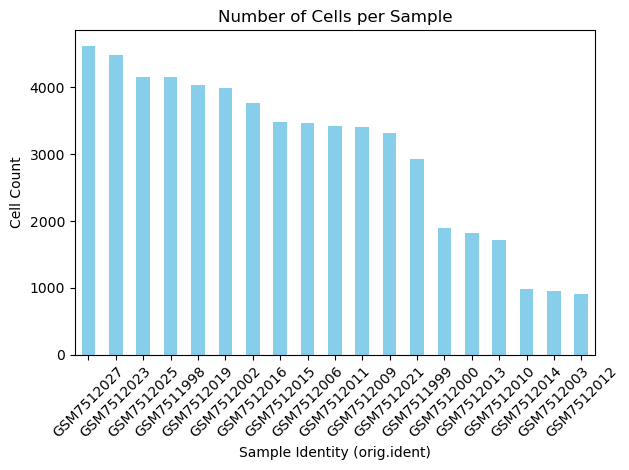

In [8]:
adata.obs['orig.ident'].value_counts().plot(kind='bar', color='skyblue')

plt.title('Number of Cells per Sample')
plt.xlabel('Sample Identity (orig.ident)')
plt.ylabel('Cell Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
adata.obs.rename(columns={'orig.ident': 'sample'}, inplace=True)
adata.obs.rename(columns={'response': 'treatment_response'}, inplace=True)

In [10]:
mapping = {'Relapse': 0, 'CCR': 1}
adata.obs['response'] = adata.obs['treatment_response'].map(mapping)
adata.obs

,sample,nCount_RNA,nFeature_RNA,percent.mt,nCount_SCT,nFeature_SCT,harmony_clusters,treatment_response,response
seurat_obj_GSM7511998_AAACCTGAGCTGTCTA-1,GSM7511998,6422.0,2157,5.185301,3790.0,1970,10,Relapse,0
seurat_obj_GSM7511998_AAACCTGCAATGGAAT-1,GSM7511998,6477.0,2178,7.796820,3764.0,1949,3,Relapse,0
seurat_obj_GSM7511998_AAACCTGCAGTATAAG-1,GSM7511998,2647.0,1223,3.853419,2872.0,1217,3,Relapse,0
seurat_obj_GSM7511998_AAACCTGCATCAGTAC-1,GSM7511998,2767.0,1250,4.336827,2914.0,1227,1,Relapse,0
seurat_obj_GSM7511998_AAACCTGGTATATGAG-1,GSM7511998,3246.0,1408,3.727665,3177.0,1395,3,Relapse,0
...,...,...,...,...,...,...,...,...,...
seurat_obj_GSM7512027_TTTGTTGTCCACGTGG-1,GSM7512027,5907.0,1238,3.622820,8945.0,1230,5,CCR,1
seurat_obj_GSM7512027_TTTGTTGTCCCGAGAC-1,GSM7512027,3173.0,913,12.763946,8667.0,1171,1,CCR,1
seurat_obj_GSM7512027_TTTGTTGTCCGGTAAT-1,GSM7512027,5188.0,999,4.838088,9035.0,1004,5,CCR,1
seurat_obj_GSM7512027_TTTGTTGTCGGCACTG-1,GSM7512027,8585.0,2060,9.085614,9143.0,2046,14,CCR,1


In [24]:
output_dir = "C:/Users/jhous/Documents/scRNA_AML_Response_Prediction/GSE235923_ped_AML_6rel_14resp"
precise = Precise(
    adata,
    model_name='XGBoostClassifier',
    output_dir=output_dir,
    target_column="response",  # Adjust based on your dataset
    sample_column="sample"
)
prediction_results = precise.cv_prediction()
sample_results, auc, estimators = prediction_results

Starting LOO Prediction with 57520 cells and 22381 features.
Sample column: sample, Target column: response.
Using Leave-One-Out cross-validation with 19 splits.

=== Fold 1 ===
Processed 1 samples
Sample	Label	Score
GSM7511998	0.0	0.4182

=== Fold 2 ===
Processed 1 samples
Sample	Label	Score
GSM7511999	0.0	0.7189

=== Fold 3 ===
Processed 1 samples
Sample	Label	Score
GSM7512000	0.0	0.1026

=== Fold 4 ===
Processed 1 samples
Sample	Label	Score
GSM7512002	0.0	0.0030

=== Fold 5 ===
Processed 1 samples
Sample	Label	Score
GSM7512003	0.0	0.0984

=== Fold 6 ===
Processed 1 samples
Sample	Label	Score
GSM7512006	0.0	0.8102

=== Fold 7 ===
Processed 1 samples
Sample	Label	Score
GSM7512009	1.0	0.1170

=== Fold 8 ===
Processed 1 samples
Sample	Label	Score
GSM7512010	1.0	0.2347

=== Fold 9 ===
Processed 1 samples
Sample	Label	Score
GSM7512011	1.0	0.8686

=== Fold 10 ===
Processed 1 samples
Sample	Label	Score
GSM7512012	1.0	1.0000

=== Fold 11 ===
Processed 1 samples
Sample	Label	Score
GSM7512013	

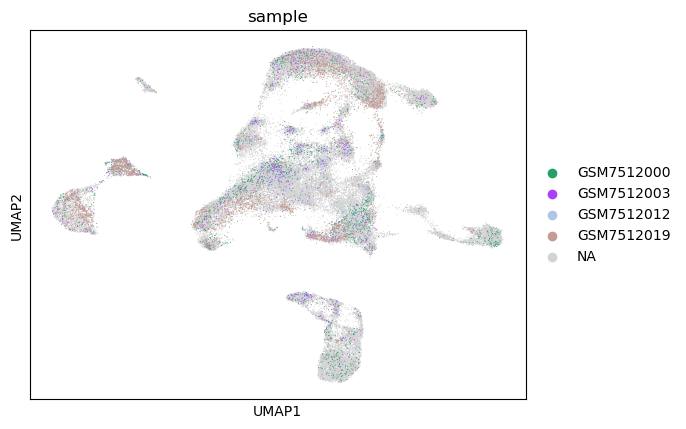

In [19]:
adata.obsm['X_umap'] = adata.obsm['X_harmony_umap'].copy()
sc.pl.umap(adata, color='sample', groups = ['GSM7512000', 'GSM7512003', 'GSM7512012', 'GSM7512019'])

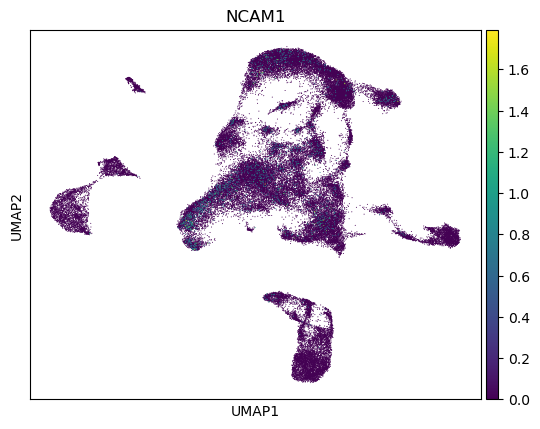

In [20]:
sc.pl.umap(adata, color='NCAM1' )

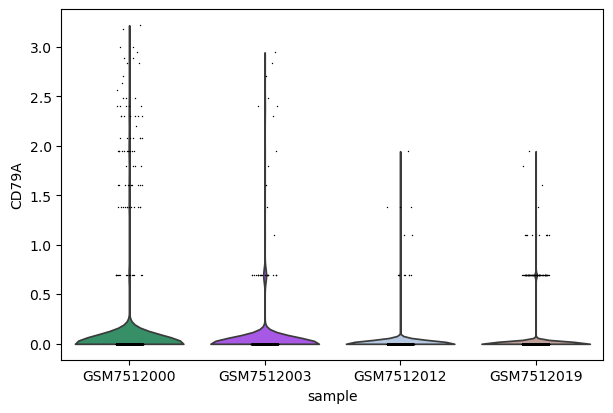

In [21]:
sc.pl.violin(adata, ['CD79A'], groupby="sample", order = ['GSM7512000', 'GSM7512003', 'GSM7512012', 'GSM7512019'] )

In [22]:
adata_subset = adata[adata.obs['sample'].isin(['GSM7512000', 'GSM7512003', 'GSM7512012', 'GSM7512019'])].copy()

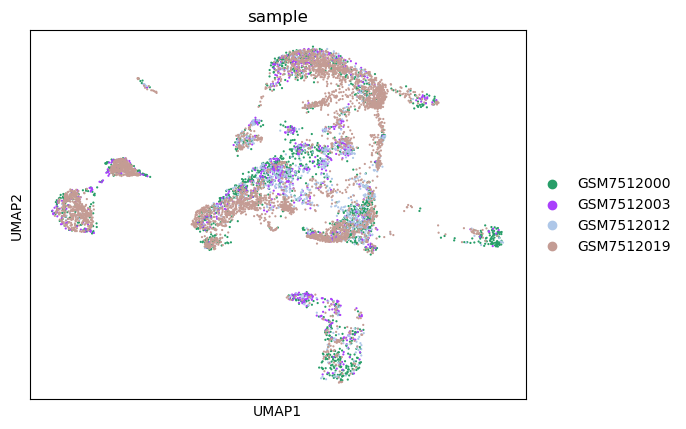

In [23]:
sc.pl.umap(adata_subset, color='sample', s=10)

In [17]:
adata.obsm['X_umap'] = adata.obsm['X_harmony_umap'].copy()

In [25]:
top_features = precise.choose_top_features(10)
top_features

['AREG',
 'LAMP5',
 'SOCS2',
 'PPP1R27',
 'TKTL1',
 'CEBPD',
 'RPL41',
 'HOXA9',
 'MT-ATP8',
 'LINC01578',
 'SNHG29']

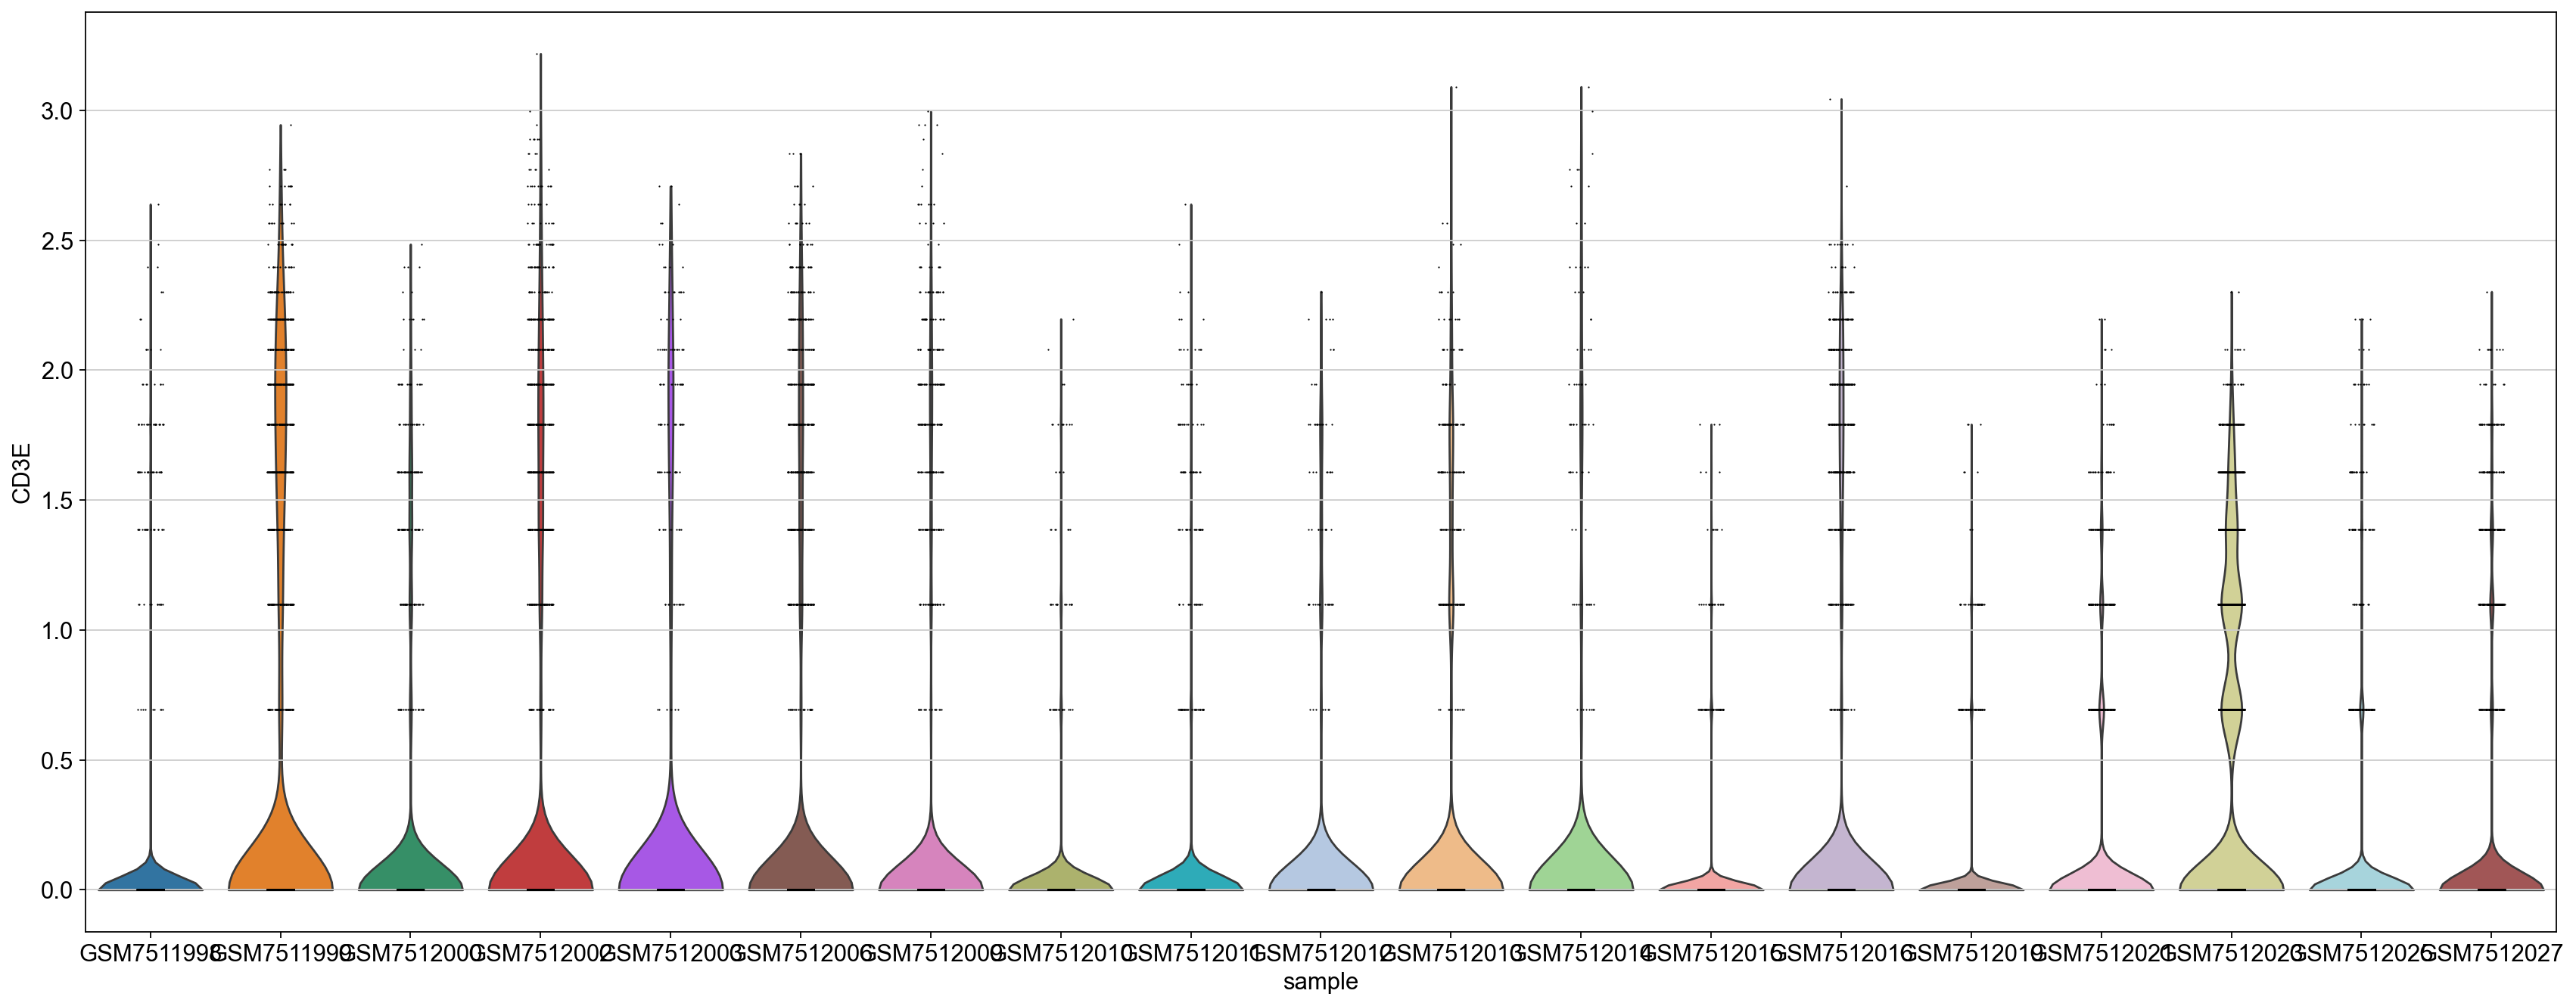

In [30]:
sc.set_figure_params(facecolor='white', figsize=(20, 10))
sc.pl.violin(adata, ['CD3E'], groupby="sample", use_raw=False)

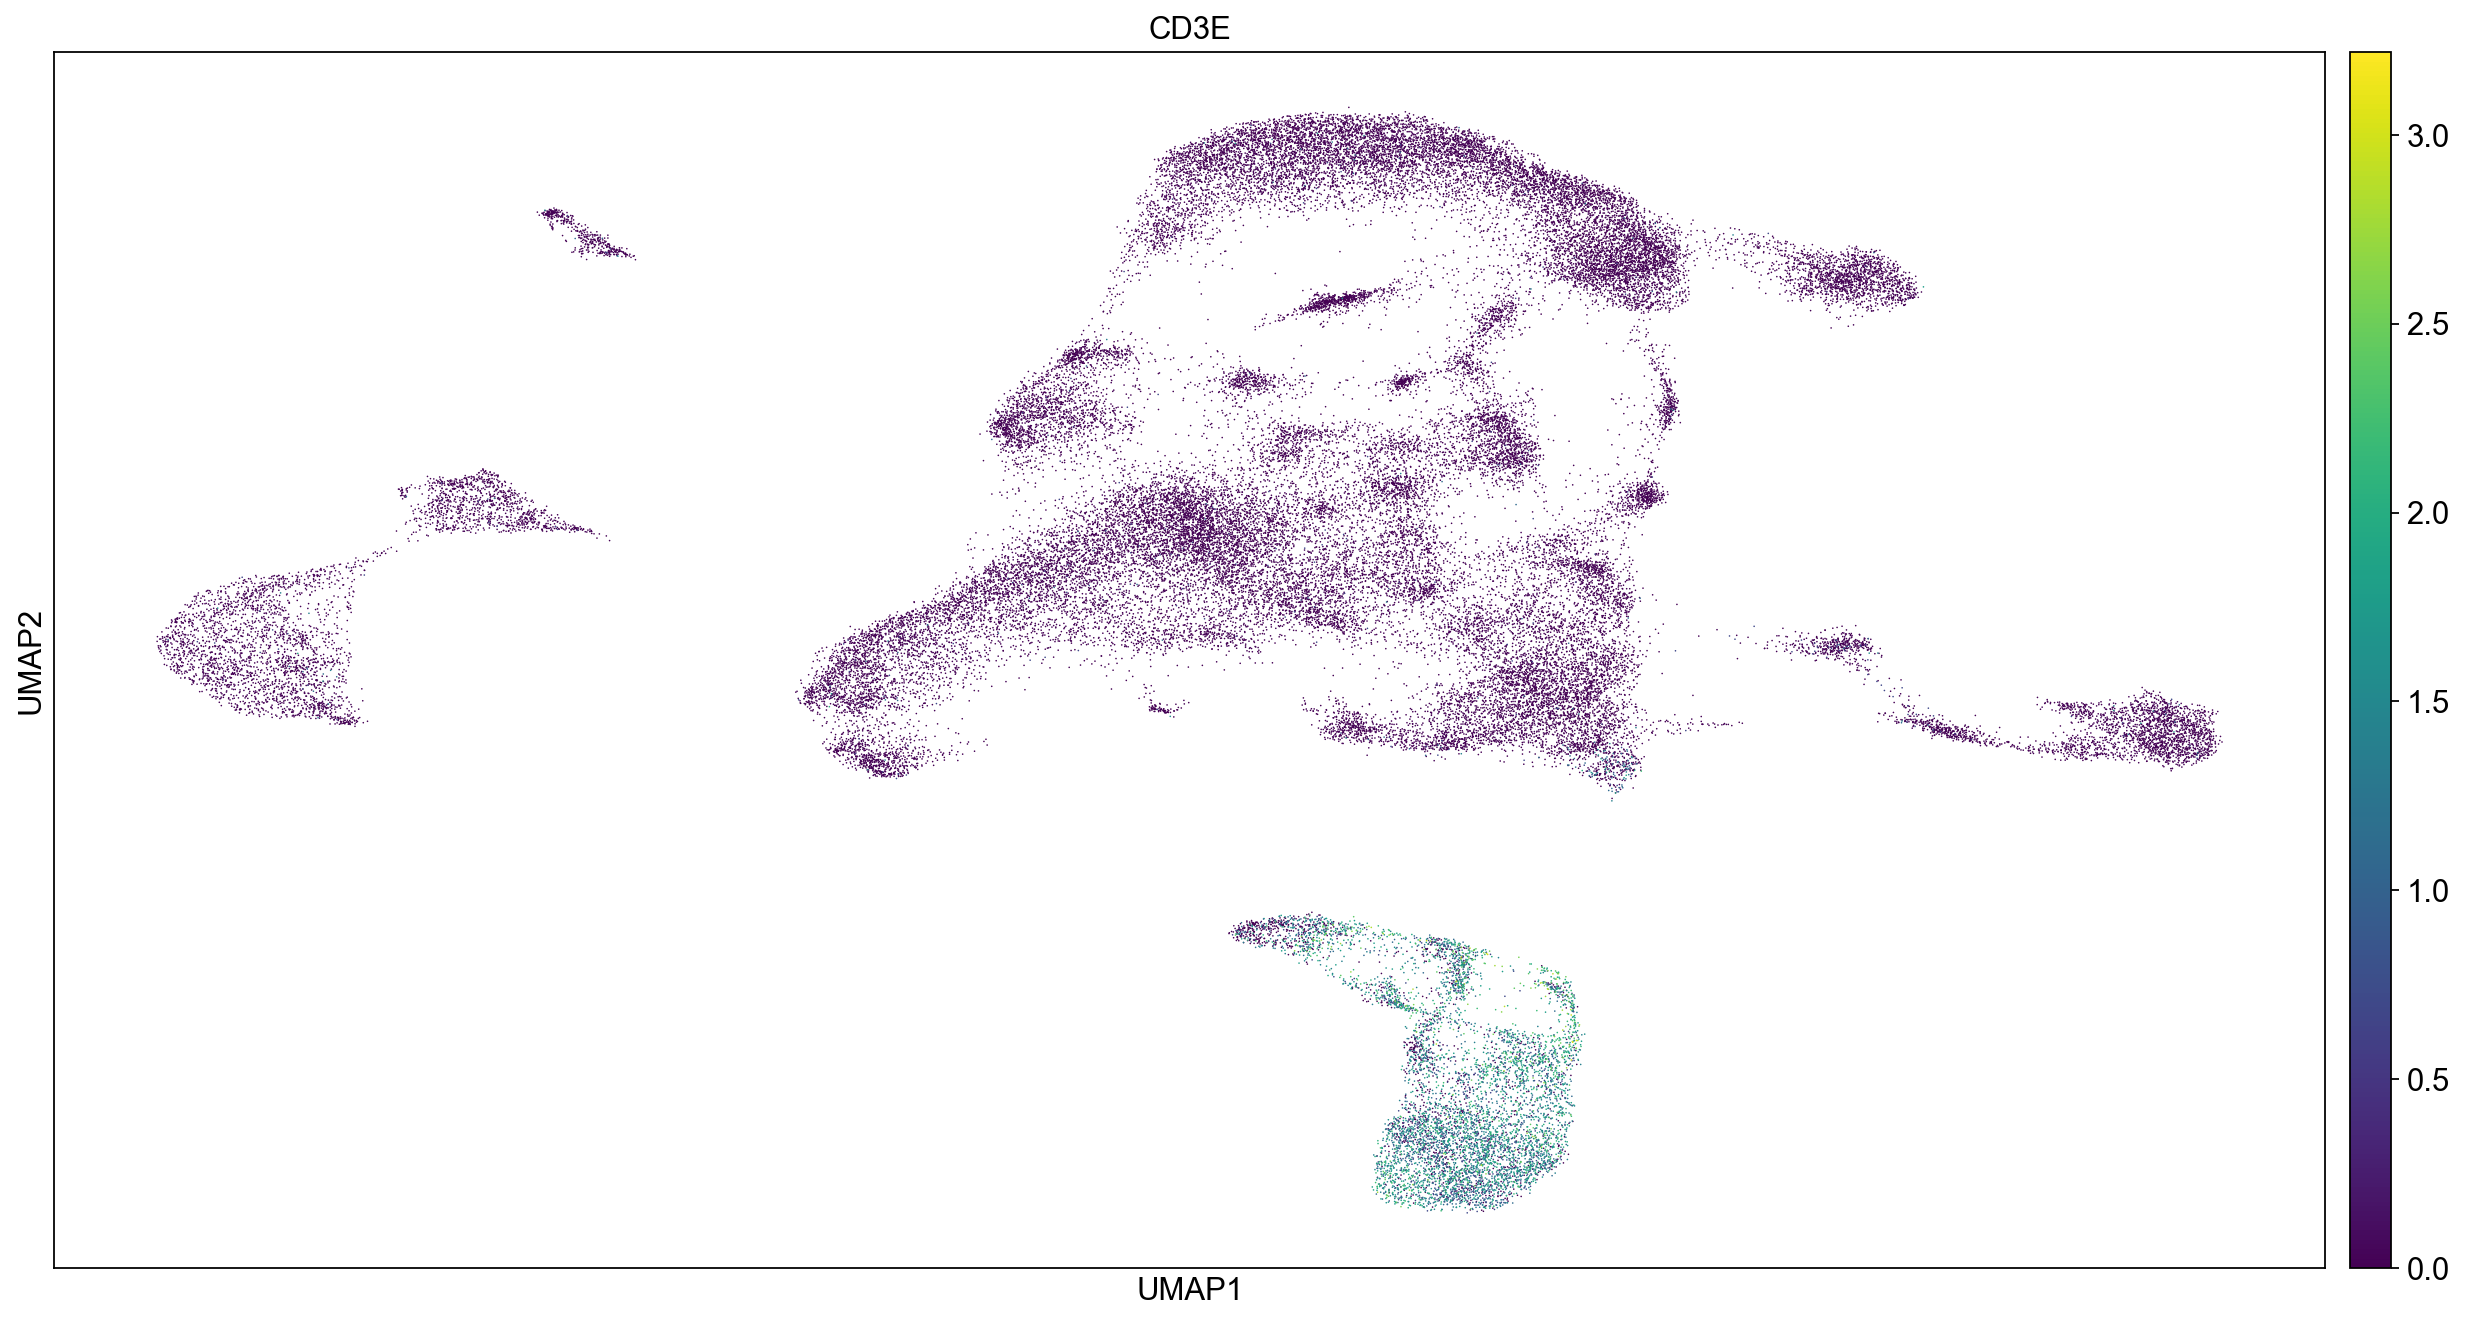

In [38]:
sc.pl.umap(
    adata,
    color="CD3E"
)